In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import nltk

from sumy.parsers.plaintext import PlaintextParser
from sumy.nlp.tokenizers import Tokenizer
from sumy.summarizers.text_rank import TextRankSummarizer

from rouge_score import rouge_scorer
from bert_score import score

print("All libraries imported successfully!")

C:\Users\Lapzone.pk\AppData\Roaming\Python\Python314\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


All libraries imported successfully!


PDF read and word count check

In [2]:
from pathlib import Path
from pypdf import PdfReader

folder = Path(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents")
pdf_files = list(folder.glob("*.pdf"))

print("PDF files found:", len(pdf_files))

for pdf_path in pdf_files:
    reader = PdfReader(str(pdf_path))
    text = "\n".join(page.extract_text() or "" for page in reader.pages)

    print("\nFile:", pdf_path.name)
    print("Pages:", len(reader.pages))
    print("Word count:", len(text.split()))
    print("\nFirst 500 characters:\n", text[:500])

PDF files found: 7

File: Customs_act 1969.pdf
Pages: 279
Word count: 104421

First 500 characters:
  
 
GOVERNMENT OF PAKISTAN 
REVENUE DIVISION 
FEDERAL BOARD OF REVENUE 
***** 
 
 
 
 
 
THE CUSTOMS ACT, 1969 
(IV OF 1969) 
 
 
 
 
 
 
 
 
As amended up to 30th June, 2025 
 
 
 
 
 
Published by: 
Printing & Publication Customs Budget 
FBR, Islamabad. 
THE CUSTOMS ACT, 1969 
i 
 
 CONTENTS  
 
 
CHAPTER I  
 
 
PRELIMINARY 
 
Section 
 
Page 
No.    
1 Short title, extent and commencement. 1    
2 Definitions. 1    
 
CHAPTER II 
 
   
 
APPOINTMENT OF OFFICERS OF 
 
 
CUSTOMS AND THEIR POWE

File: Fedral Excise 2005.pdf
Pages: 103
Word count: 34424

First 500 characters:
 The Federal Excise Act, 2005 
 
i 
 
 
 
 
 
 
 
  
 
 
The  
Federal Excise Act, 2005 
 
As amended up to 30th June, 2026 
 
The amendments made through  
 
Finance Act, 2026 
have been shown in Red  
 
 
(Any inadvertent error may kindly be reported for necessary correction to the following 
telephone contacts o

Document validation

In [3]:
for pdf_path in pdf_files:
    reader = PdfReader(str(pdf_path))
    text = "\n".join(page.extract_text() or "" for page in reader.pages).strip()
    word_count = len(text.split())

    print("Document:", pdf_path.name)
    print("Word count:", word_count)

    if word_count >= 500:
        print("Status: PASS")
    else:
        print("Status: FAIL - 500 words se kam hain")

    if not text:
        print("Warning: PDF se text extract nahi hua")

    print("-" * 40)

Document: Customs_act 1969.pdf
Word count: 104421
Status: PASS
----------------------------------------
Document: Fedral Excise 2005.pdf
Word count: 34424
Status: PASS
----------------------------------------
Document: Fedral_Tax_Ombudsman_Ordinance_2002.pdf
Word count: 6134
Status: PASS
----------------------------------------
Document: IncomeTaxRules2002.pdf
Word count: 147762
Status: PASS
----------------------------------------
Document: Income_Tax.pdf
Word count: 328459
Status: PASS
----------------------------------------
Document: sales tax 1990.pdf
Word count: 72660
Status: PASS
----------------------------------------
Document: SalesTaxRules.pdf
Word count: 79125
Status: PASS
----------------------------------------


In [4]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Income_Tax.pdf")

text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

print("Total pages:", len(reader.pages))
print("\nFirst 1000 characters:\n")
print(text[:1000])

Total pages: 839

First 1000 characters:

 
 
137 
 
 
 
 
 
GOVERNMENT OF PAKISTAN 
FEDERAL BOARD OF REVENUE 
(REVENUE DIVISION) 
…. 
 
 
 
  
INCOME TAX MANUAL 
 
PART I 
 
  
 
 
INCOME TAX ORDINANCE, 2001 
 
 
AMENDED UPTO 30TH JUNE, 2026 
 
 
 
 
 
 
 
 
 
 
 ..
 ..
TABLE OF CONTENTS 
 
SECTIONS CHAPTER 1 PRELIMINARY PAGE NO. 
1. Short title, extent and commencement 1 
2. Definitions 1 
3. Ordinance to override other laws 32 
 CHAPTER II 
CHARGE OF TAX 
 
4. Tax on taxable income 33 
4A. Omitted by Finance Act 2014 34 
4AB. Subject to this Ordinance, a surcharge payable 34 
4B. Super tax for rehabilitation of temporary displaced persons. 34 
4C. Super tax on high earning persons. 35 
5. Tax on dividends 36 
5A. Tax on undistributed Profits. 37 
5AA. Tan on return on investments in Sukuks. 37 
6. Tax on certain payments to non-residents 38 
6A. Tax on payments for digital transactions in e-commerce platforms 39 
7. Tax on shipping and air transport income of a non-resident 
person 

In [5]:
document_1 = {
    "title": "Income Tax Ordinance, 2001",
    "file": "Income_Tax.pdf",
    "pages": len(reader.pages),
    "word_count": len(text.split()),
    "source": "Federal Board of Revenue, Government of Pakistan",
    "amended_upto": "2026-06-30"
}

print("Document Details")
print("-" * 35)

for key, value in document_1.items():
    print(f"{key}: {value}")

Document Details
-----------------------------------
title: Income Tax Ordinance, 2001
file: Income_Tax.pdf
pages: 839
word_count: 328459
source: Federal Board of Revenue, Government of Pakistan
amended_upto: 2026-06-30


In [6]:
#Reference Summary
for i, page in enumerate(reader.pages):
    page_text = page.extract_text() or ""

    if "CHARGE OF TAX" in page_text and len(page_text.strip()) > 500:
        print("Page number:", i + 1)
        print(page_text[:2500])
        break

Page number: 2
TABLE OF CONTENTS 
 
SECTIONS CHAPTER 1 PRELIMINARY PAGE NO. 
1. Short title, extent and commencement 1 
2. Definitions 1 
3. Ordinance to override other laws 32 
 CHAPTER II 
CHARGE OF TAX 
 
4. Tax on taxable income 33 
4A. Omitted by Finance Act 2014 34 
4AB. Subject to this Ordinance, a surcharge payable 34 
4B. Super tax for rehabilitation of temporary displaced persons. 34 
4C. Super tax on high earning persons. 35 
5. Tax on dividends 36 
5A. Tax on undistributed Profits. 37 
5AA. Tan on return on investments in Sukuks. 37 
6. Tax on certain payments to non-residents 38 
6A. Tax on payments for digital transactions in e-commerce platforms 39 
7. Tax on shipping and air transport income of a non-resident 
person 
39 
7A. Tax on shipping of a resident person. 40 
7B. Tax on profit on debt 41 
7C. Tax on builders 41 
7D. Tax on developers 42 
7E. Omitted by the Finance Act, 2026. 43 
7F. Tax on Builders and Developers 44 
7G. Tax on certain payments by life insurance

In [7]:
#saving the reference summary to a variable
reference_summary_1 = """
The Income Tax Ordinance, 2001 provides the legal framework for income
taxation in Pakistan. It covers provisions relating to taxable income and
different categories of income subject to tax. The ordinance also contains
rules concerning tax treatment for certain payments and taxpayers.
Its chapters organize legal provisions and requirements for administering
income tax. The applicable provisions and amendments should be checked
against the official version relevant to the tax period.
"""

print("Reference Summary:")
print(reference_summary_1)

print("\nSentence count:", len([
    s for s in reference_summary_1.split(".") if s.strip()
]))

Reference Summary:

The Income Tax Ordinance, 2001 provides the legal framework for income
taxation in Pakistan. It covers provisions relating to taxable income and
different categories of income subject to tax. The ordinance also contains
rules concerning tax treatment for certain payments and taxpayers.
Its chapters organize legal provisions and requirements for administering
income tax. The applicable provisions and amendments should be checked
against the official version relevant to the tax period.


Sentence count: 5


In [8]:
#linking document details and reference summary in a dataset
import pandas as pd

dataset = pd.DataFrame([
    {
        "document_id": 1,
        "title": "Income Tax Ordinance, 2001",
        "file": "Income_Tax.pdf",
        "word_count": len(text.split()),
        "reference_summary": reference_summary_1
    }
])

display(dataset)

,document_id,title,file,word_count,reference_summary
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459,"\nThe Income Tax Ordinance, 2001 provides the ..."


In [9]:
#checking the number of sentences in the reference summary and the number of documents in the dataset
import re

summary_sentences = [
    s.strip()
    for s in re.split(r'(?<=[.!?])\s+', reference_summary_1.strip())
    if s.strip()
]

print("Reference summary sentences:", len(summary_sentences))
print("Documents in dataset:", len(dataset))
print("PDF files in folder:", len(list(folder.glob("*.pdf"))))

if len(summary_sentences) == 5:
    print("Summary check: PASS")
else:
    print("Summary check: FAIL")

Reference summary sentences: 5
Documents in dataset: 1
PDF files in folder: 7
Summary check: PASS


In [10]:
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\sales tax 1990.pdf")

reader = PdfReader(pdf_path)
sales_tax_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(sales_tax_text.split())

print("Document: Sales_Tax.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Sales_Tax.pdf
Pages: 229
Word count: 72660
Status: PASS


In [11]:
#adding more documents to the dataset
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\sales tax 1990.pdf")

reader = PdfReader(pdf_path)
sales_tax_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(sales_tax_text.split())

print("Document: Sales_Tax.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Sales_Tax.pdf
Pages: 229
Word count: 72660
Status: PASS


In [12]:
#saving the 2nd reference summary to a variable
reference_summary_2 = """
The Sales Tax Act, 1990 provides the legal framework for sales tax in Pakistan.
It defines rules concerning the collection and payment of sales tax.
The Act contains provisions related to taxable supplies and imported goods.
It also establishes requirements and procedures for registered persons.
The applicable provisions should be checked against the official version for the relevant tax period.
"""

dataset.loc[len(dataset)] = {
    "document_id": 2,
    "title": "Sales Tax Act, 1990",
    "file": "Sales_Tax.pdf",
    "word_count": len(sales_tax_text.split()),
    "reference_summary": reference_summary_2
}

display(dataset[["document_id", "title", "file", "word_count"]])

,document_id,title,file,word_count
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459
1,2,"Sales Tax Act, 1990",Sales_Tax.pdf,72660


In [13]:
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Fedral Excise 2005.pdf")

reader = PdfReader(pdf_path)
excise_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(excise_text.split())

print("Document: Federal_Excise.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Federal_Excise.pdf
Pages: 103
Word count: 34424
Status: PASS


In [14]:
reference_summary_3 = """
The Federal Excise Act, 2005 establishes the legal framework for federal excise duty in Pakistan.
It specifies goods and services that may be subject to excise duty.
The Act contains provisions concerning the assessment and collection of duty.
It also describes obligations and procedures relevant to taxpayers.
The applicable rules and amendments should be checked in the official version for the relevant tax period.
"""

dataset.loc[len(dataset)] = {
    "document_id": 3,
    "title": "Federal Excise Act, 2005",
    "file": "Federal_Excise.pdf",
    "word_count": len(excise_text.split()),
    "reference_summary": reference_summary_3
}

display(dataset[["document_id", "title", "file", "word_count"]])

,document_id,title,file,word_count
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459
1,2,"Sales Tax Act, 1990",Sales_Tax.pdf,72660
2,3,"Federal Excise Act, 2005",Federal_Excise.pdf,34424


In [15]:
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Customs_act 1969.pdf")

reader = PdfReader(pdf_path)
customs_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(customs_text.split())

print("Document: Customs_Act.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Customs_Act.pdf
Pages: 279
Word count: 104421
Status: PASS


In [16]:
reference_summary_4 = """
The Customs Act, 1969 provides the legal framework for customs administration in Pakistan.
It covers rules concerning the import and export of goods.
The Act includes provisions for customs duties and the assessment of imported goods.
It also addresses procedures and responsibilities related to customs enforcement.
The applicable provisions should be checked against the official version for the relevant period.
"""

dataset.loc[len(dataset)] = {
    "document_id": 4,
    "title": "Customs Act, 1969",
    "file": "Customs_Act.pdf",
    "word_count": len(customs_text.split()),
    "reference_summary": reference_summary_4
}

display(dataset[["document_id", "title", "file", "word_count"]])

,document_id,title,file,word_count
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459
1,2,"Sales Tax Act, 1990",Sales_Tax.pdf,72660
2,3,"Federal Excise Act, 2005",Federal_Excise.pdf,34424
3,4,"Customs Act, 1969",Customs_Act.pdf,104421


In [17]:
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\IncomeTaxRules2002.pdf")

reader = PdfReader(pdf_path)
rules_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(rules_text.split())

print("Document: Income_Tax_Rules.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Income_Tax_Rules.pdf
Pages: 1198
Word count: 147762
Status: PASS


In [18]:
reference_summary_5 = """
The Income Tax Rules, 2002 provide procedures for implementing income tax law in Pakistan.
They describe administrative requirements associated with income tax compliance.
The rules include procedures and documentation requirements for relevant taxpayers.
They support the application of the Income Tax Ordinance and its related provisions.
The applicable rules should be verified against the official version for the relevant tax period.
"""

dataset.loc[len(dataset)] = {
    "document_id": 5,
    "title": "Income Tax Rules, 2002",
    "file": "Income_Tax_Rules.pdf",
    "word_count": len(rules_text.split()),
    "reference_summary": reference_summary_5
}

display(dataset[["document_id", "title", "file", "word_count"]])

,document_id,title,file,word_count
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459
1,2,"Sales Tax Act, 1990",Sales_Tax.pdf,72660
2,3,"Federal Excise Act, 2005",Federal_Excise.pdf,34424
3,4,"Customs Act, 1969",Customs_Act.pdf,104421
4,5,"Income Tax Rules, 2002",Income_Tax_Rules.pdf,147762


In [19]:
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\SalesTaxRules.pdf")

reader = PdfReader(pdf_path)
sales_rules_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(sales_rules_text.split())

print("Document: Sales_Tax_Rules.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Sales_Tax_Rules.pdf
Pages: 232
Word count: 79125
Status: PASS


In [20]:
reference_summary_6 = """
The Sales Tax Rules, 2006 provide procedures for administering sales tax in Pakistan.
They explain compliance requirements associated with sales tax legislation.
The rules include procedural guidance and documentation requirements for relevant persons.
They support the implementation of the Sales Tax Act and related provisions.
The applicable rules should be checked against the official version for the relevant tax period.
"""

dataset.loc[len(dataset)] = {
    "document_id": 6,
    "title": "Sales Tax Rules, 2006",
    "file": "Sales_Tax_Rules.pdf",
    "word_count": len(sales_rules_text.split()),
    "reference_summary": reference_summary_6
}

display(dataset[["document_id", "title", "file", "word_count"]])

,document_id,title,file,word_count
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459
1,2,"Sales Tax Act, 1990",Sales_Tax.pdf,72660
2,3,"Federal Excise Act, 2005",Federal_Excise.pdf,34424
3,4,"Customs Act, 1969",Customs_Act.pdf,104421
4,5,"Income Tax Rules, 2002",Income_Tax_Rules.pdf,147762
5,6,"Sales Tax Rules, 2006",Sales_Tax_Rules.pdf,79125


In [21]:
from pypdf import PdfReader

pdf_path = (r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Fedral_Tax_Ombudsman_Ordinance_2002.pdf")

reader = PdfReader(pdf_path)
ombudsman_text = "\n".join(
    page.extract_text() or ""
    for page in reader.pages
)

word_count = len(ombudsman_text.split())

print("Document: Federal_Tax_Ombudsman.pdf")
print("Pages:", len(reader.pages))
print("Word count:", word_count)
print("Status:", "PASS" if word_count >= 500 else "FAIL")

Document: Federal_Tax_Ombudsman.pdf
Pages: 16
Word count: 6134
Status: PASS


In [22]:
reference_summary_7 = """
The Federal Tax Ombudsman Ordinance, 2000 establishes the office of the Federal Tax Ombudsman in Pakistan.
It provides a mechanism for addressing complaints about maladministration by tax authorities.
The ordinance describes the role and powers of the Federal Tax Ombudsman.
It outlines procedures for receiving and investigating complaints.
The applicable provisions should be checked against the official version of the ordinance.
"""

dataset.loc[len(dataset)] = {
    "document_id": 7,
    "title": "Federal Tax Ombudsman Ordinance, 2000",
    "file": "Federal_Tax_Ombudsman.pdf",
    "word_count": len(ombudsman_text.split()),
    "reference_summary": reference_summary_7
}

display(dataset[["document_id", "title", "file", "word_count"]])
print("Total documents:", len(dataset))

,document_id,title,file,word_count
0,1,"Income Tax Ordinance, 2001",Income_Tax.pdf,328459
1,2,"Sales Tax Act, 1990",Sales_Tax.pdf,72660
2,3,"Federal Excise Act, 2005",Federal_Excise.pdf,34424
3,4,"Customs Act, 1969",Customs_Act.pdf,104421
4,5,"Income Tax Rules, 2002",Income_Tax_Rules.pdf,147762
5,6,"Sales Tax Rules, 2006",Sales_Tax_Rules.pdf,79125
6,7,"Federal Tax Ombudsman Ordinance, 2000",Federal_Tax_Ombudsman.pdf,6134


Total documents: 7


# TextRank summariser function

In [23]:
def extractive_summary(document_text, sentences_count=5):
    parser = PlaintextParser.from_string(
        document_text,
        Tokenizer("english")
    )

    summarizer = TextRankSummarizer()
    summary_sentences = summarizer(
        parser.document,
        sentences_count
    )

    return " ".join(str(sentence) for sentence in summary_sentences)

In [24]:
import nltk

nltk.download('punkt_tab')
nltk.download('punkt')

[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Lapzone.pk\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Lapzone.pk\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

# TextRank test

In [26]:
test_text = text[:10000]

extractive_result_1 = extractive_summary(
    test_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — DOCUMENT 1")
print(extractive_result_1)

EXTRACTIVE SUMMARY — DOCUMENT 1
Rationalization of rates of withholding taxes in the nature of minimum tax. Principles of taxation of associations of persons 159 93. Disposal of business by association of persons to wholly-owned company 162 97. Discontinuance of business or dissolution of an association of persons 168 98C. Special provisions relating to the production of oil and natural gas, and exploration and extraction of other mineral deposits 174 100A.


In [27]:
# Find the start of actual content
start_index = text.find("CHAPTER I")

print("Chapter I position:", start_index)

if start_index != -1:
    content_text = text[start_index:start_index + 10000]
else:
    content_text = text[10000:20000]

print(content_text[:1000])

Chapter I position: 394
CHAPTER II 
CHARGE OF TAX 
 
4. Tax on taxable income 33 
4A. Omitted by Finance Act 2014 34 
4AB. Subject to this Ordinance, a surcharge payable 34 
4B. Super tax for rehabilitation of temporary displaced persons. 34 
4C. Super tax on high earning persons. 35 
5. Tax on dividends 36 
5A. Tax on undistributed Profits. 37 
5AA. Tan on return on investments in Sukuks. 37 
6. Tax on certain payments to non-residents 38 
6A. Tax on payments for digital transactions in e-commerce platforms 39 
7. Tax on shipping and air transport income of a non-resident 
person 
39 
7A. Tax on shipping of a resident person. 40 
7B. Tax on profit on debt 41 
7C. Tax on builders 41 
7D. Tax on developers 42 
7E. Omitted by the Finance Act, 2026. 43 
7F. Tax on Builders and Developers 44 
7G. Tax on certain payments by life insurance business 45 
8. General provisions relating to taxes imposed under sections 5, 6 
and 7 
45 
 CHAPTER III 
TAX ON TAXABLE INCOME 
 
 PART I 
COMPUTATION O

In [28]:
#Section 1: Short title, extent and commencement ko locate karega
for keyword in [
    "Short title, extent and commencement",
    "This Ordinance may be called",
    "CHAPTER I"
]:
    print(keyword, "->", text.find(keyword))

Short title, extent and commencement -> 295
This Ordinance may be called -> -1
CHAPTER I -> 394


In [ ]:
#Checking section 1 context
print(text[20000:23000])

d by the Finance Act, 2018 442 
214E. Inserted by the Finance Supplementary (Amendment) Act, 2018 442 
215. Furnishing of returns, documents etc. 443 
216. Disclosure of information by a public servant 444 
216A. Omitted by the Finance Act, 2022 449 
217. Forms and notices; authentication of documents 450 
218. Service of notices and other documents 450 
219. Tax or refund to be computed to the nearest Rupee 452 
220. Receipts for amounts paid 452 
221. Rectification of mistakes 452 
222. Appointment of expert 453 
222A. Fee and service charges 453 
223. Appearance by authorized representative 453 
224. Proceedings under the Ordinance to be judicial proceedings 456 
225. Proceedings against companies under liquidation 456 
226. Computation of limitation period 456 
227. Bar of suits in Civil Courts 456 
227A. Reward to officers and officials of Inland Revenue 457 
227B. Reward of whistleblowers 457 
227BA. Reward and benefits for certain persons 458 
227C Omitted through Finance Act 20

In [33]:
from pypdf import PdfReader

reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Income_Tax.pdf")

print("Total pages:", len(reader.pages))

Total pages: 839


In [34]:
for i in range(29, 60):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:250].replace("\n", " "))


--- PDF Page 30 ---
Chapter I – Preliminary__________________________________    11    1[(19A) “Eligible Person”, for the purpose of Voluntary Pension System Rules,  2005, means an individual Pakistani who 2[holds] a valid National Tax  Number3[or Computerized National 

--- PDF Page 31 ---
Chapter I – Preliminary__________________________________    12    several electronic resources and any other information in electronic  form;]    1[(19D) “electronic resource” includes telecommunication systems, transmission  devices, electronic vid

--- PDF Page 32 ---
Chapter I – Preliminary__________________________________    13    1[   ]    2[   ]    3[(22AA) “fair market value” means value as provided in section 68;]    4[(22B)  ”fee for offshore digital services” means any consideration for providing  or rend

--- PDF Page 33 ---
Chapter I – Preliminary__________________________________    14    (24) “financial institution” means an institution 1[as defined] under the  2[Companies Act, 2017

In [35]:
for i in range(29, 60):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:250].replace("\n", " "))


--- PDF Page 30 ---
Chapter I – Preliminary__________________________________    11    1[(19A) “Eligible Person”, for the purpose of Voluntary Pension System Rules,  2005, means an individual Pakistani who 2[holds] a valid National Tax  Number3[or Computerized National 

--- PDF Page 31 ---
Chapter I – Preliminary__________________________________    12    several electronic resources and any other information in electronic  form;]    1[(19D) “electronic resource” includes telecommunication systems, transmission  devices, electronic vid

--- PDF Page 32 ---
Chapter I – Preliminary__________________________________    13    1[   ]    2[   ]    3[(22AA) “fair market value” means value as provided in section 68;]    4[(22B)  ”fee for offshore digital services” means any consideration for providing  or rend

--- PDF Page 33 ---
Chapter I – Preliminary__________________________________    14    (24) “financial institution” means an institution 1[as defined] under the  2[Companies Act, 2017

In [36]:
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(51, 56)
)

extractive_result_1 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — INCOME TAX")
print(extractive_result_1)

EXTRACTIVE SUMMARY — INCOME TAX
(2) The income tax payable by a taxpayer for a tax year shall be computed by applying the rate or rates of tax applicable to the taxpayer under this Ordinance to the taxable income of the taxpayer for the year, and from the resulting amount shall be subtracted any tax credits allowed to the taxpayer for the year. — (1) Subject to this Ordinance, a surcharge shall be payable by every taxpayer at the rate of fifteen per cent of the income tax payable under this Ordinance including the tax payable under Part V of Chapter X of Chapter XIII, as the case may be, for the period commencing from the promulgation of this Ordinance, till the 30th June, 2011. (5) Where the super tax is not paid by a person liable to pay it, the Commissioner shall recover the super tax payable under subsection (1) and the provisions of Part IV,X , XI and XII of Chapter X and Part I of Chapter XI of the Ordinance shall, so far as may be, apply to the collection of super tax as these a

In [40]:
dataset.loc[0, "document_name"] = "Income Tax Ordinance, 2001"

In [66]:
dataset.loc[0, "extractive_summary"] = extractive_result_1

### Sales Tax Act, 1990 ki extractive summary

In [42]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\sales tax 1990.pdf")

print("Total pages:", len(reader.pages))

Total pages: 229


In [ ]:
# Checking first 30 pages of the PDF for content
for i in range(min(30, len(reader.pages))):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:200].replace("\n", " "))


--- PDF Page 1 ---
Sales Tax Act, 1990    1                The     Sales Tax Act, 1990                (Act No. III of 1951 as Amended  by Act VII of 1990)     As amended up to 30th June, 2026     The amendments made thr

--- PDF Page 2 ---
Sales Tax Act, 1990    2        Contents    Chapter I…………………………………………………………………...7  Preliminary…………………………………………………………  …….7  1.  Short title, extent and commencement. ............................. ………

--- PDF Page 3 ---
Sales Tax Act, 1990    3    14AC. Bar on operations of Bank Accounts……………………………..53  14AD. Bar on transfer of Immoveable Property……………………….. .54  14AE. Other measures for non-registration………..……………………

--- PDF Page 4 ---
Sales Tax Act, 1990    4    30E.  Powers and Functions of Directorate etc. ......................... ………76  31.  Powers. .............................................................................. 

--- PDF Page 5 ---
Sales Tax Act, 1990    5    APPEALS ............................................................

In [44]:
# sales tax act are starting from page 7 to 11, so we will extract text from those pages for summarization
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(6, 11)
)

extractive_result_2 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — SALES TAX")
print(extractive_result_2)

EXTRACTIVE SUMMARY — SALES TAX
(c) who fails to file an Income Tax return under section 114 or statement under section 115, of the Income Tax Ordinance, 2001(XLIX of 2001), by the due date; and- (d) who fails to file 11[quarterly] or an annual   withholding   tax statement under sectio n 165 of the Income Tax Ordinance, 2001; 15[(3A) “association of persons ” includes a firm, a Hindu undivided family, any artificial juridical person and anybody of persons formed under a foreign law, but does not include a company;] 16[(3AA) “banking company” means a banking company as defined in the Banking Companies Ordinance,  1962 (LVII of 1962) and includes anybody corporate which transacts the business of banking in Pakistan;] (6) “Customs Act” means the Customs Act, 1969 (IV of 1969), and where appropriate all rules and notifications made under that Act; 27[(6A) “defaulter” means a person and, in the case of company or firm, every director, or partner of the company, or as the case may be, of the

In [ ]:
#summary have been generated so we are saving this for evaluation pipeline
dataset.loc[1, "document_name"] = "Sales Tax Act, 1990"

In [65]:
dataset.loc[1, "extractive_summary"] = extractive_result_2

In [46]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Fedral Excise 2005.pdf")

print("Total pages:", len(reader.pages))

for i in range(min(15, len(reader.pages))):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:180].replace("\n", " "))

Total pages: 103

--- PDF Page 1 ---
The Federal Excise Act, 2005    i                       The   Federal Excise Act, 2005    As amended up to 30th June, 2026    The amendments made through     Finance Act, 2026  hav

--- PDF Page 2 ---
The Federal Excise Act, 2005    ii  Contents     Section Description Page   Chapter I – Preliminary 5  1 Short title, extent and commencement. 5  2 Definitions. 5-11   Chapter-II –

--- PDF Page 3 ---
The Federal Excise Act, 2005    iii  Section Description Page  20 Appointment of Special Judges for trial of offences 33  21 Trial of offences by Special Judge. 33  21A Appeal agai

--- PDF Page 4 ---
The Federal Excise Act, 2005    iv  Section Description Page  42 Observance of Board’s orders, directions and instructions. 55  42A Reference to authorities 55  42B Selection for a

--- PDF Page 5 ---
The Federal Excise Act, 2005    5  CHAPTER I  PRELIMINARY  1. Short title, extent and commencement. —(1) This Act may  be called the Federal Excise Act, 2005, 

In [47]:
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(4, 9)
)

extractive_result_3 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — FEDERAL EXCISE")
print(extractive_result_3)

EXTRACTIVE SUMMARY — FEDERAL EXCISE
Definitions.—In this Act, unless there is anything repugnant in the subject or context,— (1) “adjudicating authority” means any authority competent to pass any order or decision under this Act or the rules made there under , but does not include the Board or Appellate Tribunal; (2) “adjustment” means deduction of amount of duty paid on goods used in the manufacture or production of other goods from the amount of duty payable on such other  goods in the prescribed manner; 1[(2A) “algorithmic settlement mechanism”  means algorithmic settlement mechanism provided under section 47AA of the Sales Tax Act, 1990 (VII of 1990);] 2[(3) “Appellate Tribunal” means the Appellate Tribunal Inland Revenue established under section 130 of the Income  Tax Ordinance, 2001 (XLIX of 2001);] 3[(4) “Board” shall have the same meaning as defined under clause (8) of section 2 of the Income Tax Ordinance, 2001 (XLIX of 2001). ; (7) “default surcharge” means surcharge levied 

In [48]:
dataset.loc[2, "extractive_summary"] = extractive_result_3

In [64]:
dataset.loc[2, "extractive_summary"] = extractive_result_3

In [49]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Customs_act 1969.pdf")

print("Total pages:", len(reader.pages))

for i in range(min(15, len(reader.pages))):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:180].replace("\n", " "))

Total pages: 279

--- PDF Page 1 ---
    GOVERNMENT OF PAKISTAN  REVENUE DIVISION  FEDERAL BOARD OF REVENUE  *****            THE CUSTOMS ACT, 1969  (IV OF 1969)                  As amended up to 30th June, 2025      

--- PDF Page 2 ---
THE CUSTOMS ACT, 1969  i     CONTENTS       CHAPTER I       PRELIMINARY    Section    Page  No.     1 Short title, extent and commencement. 1     2 Definitions. 1       CHAPTER II 

--- PDF Page 3 ---
THE CUSTOMS ACT, 1969  ii      Section  Page  No.    3CCD Directorate General of National Targeting Centre    11  3CCE Directorate General of Combating Trade Based Money  Launderin

--- PDF Page 4 ---
THE CUSTOMS ACT, 1969  iii             Section    Page  No.    12 Power to appoint or licence public ware-houses. 16    12A. Power to appoint or licence common warehouses 17    13 

--- PDF Page 5 ---
THE CUSTOMS ACT, 1969  iv    Section  Page  No.    19A Presumption that incidence of duty has been passed on to the  buyer  26      19C Minimal duties not to b

In [50]:
for i in range(15, 25):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:220].replace("\n", " "))


--- PDF Page 16 ---
THE CUSTOMS ACT, 1969  xv    Section    Page  No.   155Q Electronic exchange of information and authentication  through the Customs Computerized System  116      155R Correction of clerical errors 116       CHAPTER XVII 

--- PDF Page 17 ---
THE CUSTOMS ACT, 1969  xvi    Section    Page  No.       167 Person escaping may be afterwards arrested. 188     168 Seizure of things liable to confiscation. 188     169 Things seized how dealt with. 189     170 Procedu

--- PDF Page 18 ---
THE CUSTOMS ACT, 1969  xvii    Section    Page  No.     180 Issue of show-cause notice before confiscation of goods or  imposition of penalty.    195  181 Option to pay fine in lieu of confiscated goods. 195     182 Vest

--- PDF Page 19 ---
THE CUSTOMS ACT, 1969  xviii        Section    Page  No.     191 Imprisonment may be of either description.    202  192 Duty of certain persons to give information.     202       CHAPTER XIX          APPEALS AND REVISION

--- PDF Page 20 ---
THE CUSTOMS

In [51]:
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(22, 27)
)

extractive_result_4 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — CUSTOMS ACT")
print(extractive_result_4)

EXTRACTIVE SUMMARY — CUSTOMS ACT
5[(a) “adjudicating authority ” means any authority competent to pass any order or decision under this Act, but does not include the Board, 6[the Collector (Appeals)] or the Appellate Tribunal;] 7,45[(ai) “advance ruling” means a written decision by the Board or any officer or a committee authorized by  the Board, on the request of an applicant for determination of classification, origin or applicability of a particular relief or exemption on goods prior to their importation or exportation, valid for a specified period of time;] 8[(aa) “agent” means a person licensed under section 207 or permitted to transact any business under section 208;” (aaa) “appellate tribunal”   means the Customs 36[…..] Appellate Tribunal constituted under section 194;] (b) 8a[“appropriate officer”, means the officer of customs to whom such functions have been assigned by or under this Act or the rules made there under;] (e) 12a[“Board” means the Central Board of Revenue  estab

In [ ]:
dataset.loc[3, "document_name"] = "Customs Act, 1969"


In [63]:
dataset.loc[3, "extractive_summary"] = extractive_result_4

In [53]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\IncomeTaxRules2002.pdf")

print("Total pages:", len(reader.pages))

for i in range(min(15, len(reader.pages))):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:180].replace("\n", " "))

Total pages: 1198

--- PDF Page 1 ---
Table of Contents         Income Tax Rules, 2002 i    GOVERNMENT OF PAKISTAN   FEDERAL BOARD OF REVENUE  (REVENUE DIVISION)      INCOME TAX MANUAL  PART II      INCOME TAX RULES, 2

--- PDF Page 2 ---
Table of Contents         Income Tax Rules, 2002 ii    INCOME TAX RULES, 2002    ARRANGEMENT OF RULES    Table of Contents    RULES TITLE PAGE NO.  CHAPTER - I CHAPTER - I 1  01 Sh

--- PDF Page 3 ---
Table of Contents         Income Tax Rules, 2002 iii    RULES TITLE PAGE NO.  PART IV COMPUTATION AND COLLECTION OF TAX UNDER SECTIONS 7C AND 7D 69  13Q Application 69  13R Definit

--- PDF Page 4 ---
Table of Contents         Income Tax Rules, 2002 iv    RULES TITLE PAGE NO.  19I Application of this rule 109  CHAPTER - VI TRANSFER PRICING-- 110  20 Application of this chapter 1

--- PDF Page 5 ---
Table of Contents         Income Tax Rules, 2002 v    RULES TITLE PAGE NO.  maintain the following minimum books of account, documents and  records-  30A Elec

In [54]:
for i in range(15, 25):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:250].replace("\n", " "))


--- PDF Page 16 ---
CHAPTER - I     Income Tax Rules, 2002 1    GOVERNMENT OF PAKISTAN  REVENUE DIVISION  1[FEDERAL] BOARD OF REVENUE  ***   Notification No.  S.R.O. 428(1)/2002 , Islamabad, the July 1, 2002. - ln  exercise of powers conferred by section 237 of the Inco

--- PDF Page 17 ---
CHAPTER - I     Income Tax Rules, 2002 2     1[(aa) "Computerized Payment Receipt" means a computer generated  receipt issued by the State Bank of Pakistan or the National Bank  of Pakistan acknowledging payment of tax;  (ab) "digital certificate" or

--- PDF Page 18 ---
CHAPTER - II DETERMINATION OF INCOME - HEADS OF  INCOME    Income Tax Rules, 2002 3    CHAPTER - II    DETERMINATION OF INCOME - HEADS OF INCOME    1[PART-l: SALARY    3. Valuation of perquisites, allowances and benefits.-    For the purposes of comp

--- PDF Page 19 ---
CHAPTER - II DETERMINATION OF INCOME - HEADS OF  INCOME    Income Tax Rules, 2002 4    (ii) For personal use  only  10% of:  (a) the cost to the employer for acqui

In [55]:
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(17, 22)
)

extractive_result_5 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — INCOME TAX RULES")
print(extractive_result_5)

EXTRACTIVE SUMMARY — INCOME TAX RULES
For the purposes of computing the income chargeable to tax under the head "salary", the value of all perquisites, allowances and benefits provided by the employer to the employee shall be included in the said income in accordance with the rules 4 to 7. (i) Partly for personal and partly for official use 5% of: (a) the cost to the employer for acquiring the motor vehicle; or, (b) the fair market value of the motor vehicle at the commencement of the lease, if the motor vehicle is  taken on lease by the employer; (ii) For personal use only 10% of: (a) the cost to the employer for acquiring the motor vehicle; or, (b) the fair market value of the motor vehicle at the commencement of the lease, if the motor vehicle is taken  on lease by the employer; and (1) For the purpose of clause (d) of section 21, which provides for a limitation on the deduction of entertainment expenditure, and subject to sub -rule (2), a deduction for entertainment expenditure sha

In [56]:
dataset.loc[4, "document_name"] = "Income Tax Rules, 2002"


In [62]:
dataset.loc[4, "extractive_summary"] = extractive_result_5

In [57]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\SalesTaxRules.pdf")

print("Total pages:", len(reader.pages))

for i in range(min(12, len(reader.pages))):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:200].replace("\n", " "))

Total pages: 232

--- PDF Page 1 ---
Sales Tax Rules, 2006  (i)        The  SALES TAX RULES, 2006      By a team of     Sales Tax & Federal Excise – Policy Wing,   Federal Board of Revenue  Islamabad          Updated up to 31st July, 202

--- PDF Page 2 ---
Sales Tax Rules, 2006  (ii)      Table of Contents  THE SALES TAX RULES, 2006 ..........................................................................................................................

--- PDF Page 3 ---
Sales Tax Rules, 2006  (iii)    21. Change in value of supply or amount of sales tax. ..................................................................................... 25  22. Adjustment of input 

--- PDF Page 4 ---
Sales Tax Rules, 2006  (iv)    36. Post-sanction audit of refund claims. ......................................................................................................... 37  37. Action on ina

--- PDF Page 5 ---
Sales Tax Rules, 2006  (v)    CHAPTER VIB…………………………………………………………………………………………………4

In [58]:
for i in range(12, 20):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:250].replace("\n", " "))


--- PDF Page 13 ---
Sales Tax Rules, 2006  (xiii)    SUB-CHAPTER 6 ............................................................................................................................................. 116  MISCELLANEOUS ..........................................

--- PDF Page 14 ---
Sales Tax Rules, 2006  (xiv)    MISCELLANEOUS .......................................................................................................................................... 124  150ZQZF. Liabilities of the vendor. ........................

--- PDF Page 15 ---
Sales Tax Rules, 2006  (xv)    CHAPTER XIV-E  WITHHOLDING OBLIGATION FOR ONLINE MARKETPLACE, PAYMENT INTERMEDIARY  AND COURIER THROUGH DIGITALLY ORDERED GOODS………………………………….……...131  150ZZM.    Application…………………………………………………………………………………………131  150ZZN.

--- PDF Page 16 ---
Sales Tax Rules, 2006  (xvi)    CHAPTER XVII-B ....................................................................................................................

In [59]:
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(17, 22)
)

extractive_result_6 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — SALES TAX RULES")
print(extractive_result_6)

EXTRACTIVE SUMMARY — SALES TAX RULES
S.R.O.555(1)/2006, dated 5th June, 2006 .--In exercise of the powers conferred by sub -section (I) of section 4, 2[section 40 and section 45A] of the Federal Excise Act, 2005, 3[***]section 50 4[and sub-section (1) of section 71] of the Sales Tax Act,1990, read with 5[sub- section (9A) of section 3,] 6[sub-section (7) of section 3]sub- section (2) of section 8 7[, 8[ 9[***] of section 8], clause (ii) of sub-section (2) of section 8B, sections9, 10,14, 21 10[,21A] and 28, clause (c) of sub-section (1) of section 22, 11[first proviso to sub-section (1) of section 23], section 26, 12[section 33] 13[, section 40C], sub-section (6) of section 47 A, sections 48, 14[ 50A, 52, 52A] and 66 thereof, the 15[Federal] Board of Revenue is pleased to make the following rules, namely:-- (iii) "adjudicating authority" means any officer appointed to Adjudicate and decide cases under section 179 of the Customs Act, 1969 (IV of 1969), section 45 of  the Sales Tax Act, 

In [60]:
dataset.loc[5, "document_name"] = "Sales Tax Rules, 2006"

In [61]:
dataset.loc[5, "extractive_summary"] = extractive_result_6

In [67]:
reader = PdfReader(r"C:\Users\Lapzone.pk\OneDrive\Desktop\ML_Intern\Text Sumarization Evaluation\Tax Documents\Fedral_Tax_Ombudsman_Ordinance_2002.pdf")

print("Total pages:", len(reader.pages))

for i in range(min(8, len(reader.pages))):
    page_text = reader.pages[i].extract_text() or ""
    print(f"\n--- PDF Page {i+1} ---")
    print(page_text[:250].replace("\n", " "))

Total pages: 16

--- PDF Page 1 ---
  Page 1 of 16        THE ESTABLISHMENT OF THE OFFICE OF FEDERAL TAX  OMBUDSMAN ORDINANCE, 2000         CONTENTS  1.  Short title, extent and commencement  2.  Definitions  3.  Appointment of Federal Tax Ombudsman  4.  Tenure of the Federal Tax Ombud

--- PDF Page 2 ---
  Page 2 of 16    21.  Authorisation of provincial functionaries  22.  Award of costs and compensation and refunds of amounts  23.  Assistance and advice to Federal Tax Ombudsman  24.  Conduct of business  25.  Requirement of affidavits  26.  Reward 

--- PDF Page 3 ---
  Page 3 of 16    THE ESTABLISHMENT OF THE OFFICE OF FEDERAL TAX  OMBUDSMAN ORDINANCE, 2000  ORDINANCE No. XXXV of 2000  [11th August, 2000]  An Ordinance to provide for the appointment of the Federal Tax Ombudsman   WHEREAS, it is expedient to provi

--- PDF Page 4 ---
  Page 4 of 16    (d)  involves the exercise of powers, or the failure or refusal to do so, for corrupt or  improper motives, such as bribery, job bery

In [68]:
content_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(2, 7)
)

extractive_result_7 = extractive_summary(
    content_text,
    sentences_count=5
)

print("EXTRACTIVE SUMMARY — FEDERAL TAX OMBUDSMAN")
print(extractive_result_7)

EXTRACTIVE SUMMARY — FEDERAL TAX OMBUDSMAN
(viii)  the Income Tax Ordinance, 1979; (XXXI of 1979) (ix)  the Import of goods (Anti -dumping and Countervailing Duties) Ordinance, 1983; (III of 1983) (x)  section 7 of the Finance Act, 1989; (V of 1989) (xi)  the Sales Tax Act, 1990; (XII of 1991) (xii)  section 12 of the Finance Act, 1991; (xiii)  such other laws having nexus with taxation as the Federal Government may, by notification in the official Gazette, specify to be the Relevant Legislation for the purposes of this Ordinance; and (xiv)  the rules, regulations and notifications, made or issued thereunder. (7)”Revenue Division" means the administrative unit responsible for the conduct of business of the Federal Government in matters relating directly or indirectly with the collection of revenue from federal taxes, levy of taxes, duties, cesses or fees and declared as such by the Federal Government, and includes all its subordinate departments, offices and agencies; (8)”Staff Member"

In [69]:
dataset.loc[6, "document_name"] = "Federal Tax Ombudsman Ordinance, 2000"
dataset.loc[6, "extractive_summary"] = extractive_result_7

### abstractive Summarization

In [70]:
print(dataset.columns.tolist())
print(dataset[["document_name", "reference_summary"]])

['document_id', 'title', 'file', 'word_count', 'reference_summary', 'extractive_summary', 'document_name']
                           document_name  \
0             Income Tax Ordinance, 2001   
1                    Sales Tax Act, 1990   
2                                    NaN   
3                      Customs Act, 1969   
4                 Income Tax Rules, 2002   
5                  Sales Tax Rules, 2006   
6  Federal Tax Ombudsman Ordinance, 2000   

                                   reference_summary  
0  \nThe Income Tax Ordinance, 2001 provides the ...  
1  \nThe Sales Tax Act, 1990 provides the legal f...  
2  \nThe Federal Excise Act, 2005 establishes the...  
3  \nThe Customs Act, 1969 provides the legal fra...  
4  \nThe Income Tax Rules, 2002 provide procedure...  
5  \nThe Sales Tax Rules, 2006 provide procedures...  
6  \nThe Federal Tax Ombudsman Ordinance, 2000 es...  


In [71]:
dataset.loc[2, "document_name"] = "Federal Excise Act, 2005"

print(dataset[["document_name", "reference_summary"]])

                           document_name  \
0             Income Tax Ordinance, 2001   
1                    Sales Tax Act, 1990   
2               Federal Excise Act, 2005   
3                      Customs Act, 1969   
4                 Income Tax Rules, 2002   
5                  Sales Tax Rules, 2006   
6  Federal Tax Ombudsman Ordinance, 2000   

                                   reference_summary  
0  \nThe Income Tax Ordinance, 2001 provides the ...  
1  \nThe Sales Tax Act, 1990 provides the legal f...  
2  \nThe Federal Excise Act, 2005 establishes the...  
3  \nThe Customs Act, 1969 provides the legal fra...  
4  \nThe Income Tax Rules, 2002 provide procedure...  
5  \nThe Sales Tax Rules, 2006 provide procedures...  
6  \nThe Federal Tax Ombudsman Ordinance, 2000 es...  


In [72]:
print("API key variable exists:", "GEMINI_API_KEY" in globals())

API key variable exists: False


In [76]:
import os
from getpass import getpass

GEMINI_API_KEY = getpass("Enter your Gemini API key: ")
os.environ["GEMINI_API_KEY"] = GEMINI_API_KEY

In [77]:
%pip install -q google-genai

Note: you may need to restart the kernel to use updated packages.


In [83]:
response = client.models.generate_content(
    model="gemini-3.5-flash-lite",
    contents="Reply with only OK.",
    config={"http_options": {"timeout": 30000}}
)

print(response.text)

OK


In [84]:
def abstractive_summary(text):
    prompt = f"""
You are a professional Pakistani tax-law summarization assistant.

Summarize the following tax document excerpt in exactly 5 sentences.
Use clear, simple English.
Preserve important legal provisions, rules, and obligations.
Do not add facts that are not present in the text.
If a detail is unclear, do not guess.

Document excerpt:
{text}
"""

    response = client.models.generate_content(
        model="gemini-3.5-flash-lite",
        contents=prompt,
        config={"http_options": {"timeout": 30000}}
    )

    return response.text.strip()

### First document summary

In [85]:
reader = PdfReader("C:\\Users\\Lapzone.pk\\OneDrive\\Desktop\\ML_Intern\\Text Sumarization Evaluation\\Tax Documents\\Income_Tax.pdf")

source_text = "\n".join(
    reader.pages[i].extract_text() or ""
    for i in range(51, 56)
)

summary = abstractive_summary(source_text)

print("ABSTRACTIVE SUMMARY")
print("=" * 50)
print(summary)

ABSTRACTIVE SUMMARY
Income tax is imposed each tax year on every person with taxable income, computed by applying applicable rates and subtracting allowed tax credits in a specific order. 
Certain classes of income are subject to separate taxation, collection, or deduction as a final tax, and are excluded from regular taxable income computations. 
A surcharge of ten percent is payable by individuals and associations of persons with taxable incomes exceeding ten million rupees, except for individuals with salary income. 
Super taxes are imposed for the rehabilitation of temporarily displaced persons and on high earning persons based on specific income calculations and statutory rates. 
Specific taxes are also charged on company dividends, undistributed profits of certain public companies, and returns on investments in sukuks.


In [ ]:
#saving the abstractive summary to the dataset
dataset.loc[0, "abstractive_summary"] = summary

print(dataset.loc[0, ["document_name", "abstractive_summary"]])

document_name                                 Income Tax Ordinance, 2001
abstractive_summary    Income tax is imposed each tax year on every p...
Name: 0, dtype: str


### Now the remaining ones

In [90]:
documents = [
    ("sales tax 1990.pdf", 1, 6, 11),
    ("Fedral Excise 2005.pdf", 2, 4, 9),
    ("Customs_act 1969.pdf", 3, 22, 27),
    ("IncomeTaxRules2002.pdf", 4, 17, 22),
    ("SalesTaxRules.pdf", 5, 17, 22),
    ("Fedral_Tax_Ombudsman_Ordinance_2002.pdf", 6, 2, 7)
]

for filename, idx, start, end in documents:
    try:
        reader = PdfReader(os.path.join("Tax Documents", filename))

        source_text = "\n".join(
            reader.pages[i].extract_text() or ""
            for i in range(start, end)
        )

        result = abstractive_summary(source_text)
        dataset.loc[idx, "abstractive_summary"] = result

        print(f"\n{dataset.loc[idx, 'document_name']}")
        print(result)
        print("-" * 50)

    except Exception as e:
        print(f"Error in {filename}: {e}")


Sales Tax Act, 1990
The Sales Tax Act of 1990 consolidates and amends the law regarding the tax levied on the sale, importation, exportation, production, manufacture, or consumption of goods throughout Pakistan. Section 2 of the Act provides definitions for various terms used within the legal framework, including abettors, active taxpayers, and arrears. It defines a cottage industry as a manufacturing concern located in a residential area without industrial utility connections, employing no more than ten workers, and having an annual turnover not exceeding eight million rupees. Furthermore, the due date for submitting a sales tax return is specified as the fifteenth day of the month following the end of the tax period, unless the Board notifies a different date. The Act also outlines definitions for organizational roles, electronic systems, and legal entities such as companies, associations of persons, and banking companies.
--------------------------------------------------

Federal 

In [91]:
print("Total documents:", len(dataset))
print("Abstractive summaries saved:",
      dataset["abstractive_summary"].notna().sum())

display(dataset[[
    "document_name",
    "reference_summary",
    "extractive_summary",
    "abstractive_summary"
]])

Total documents: 7
Abstractive summaries saved: 7


,document_name,reference_summary,extractive_summary,abstractive_summary
0,"Income Tax Ordinance, 2001","\nThe Income Tax Ordinance, 2001 provides the ...",(2) The income tax payable by a taxpayer for a...,Income tax is imposed each tax year on every p...
1,"Sales Tax Act, 1990","\nThe Sales Tax Act, 1990 provides the legal f...",(c) who fails to file an Income Tax return und...,The Sales Tax Act of 1990 consolidates and ame...
2,"Federal Excise Act, 2005","\nThe Federal Excise Act, 2005 establishes the...","Definitions.—In this Act, unless there is anyt...","The Federal Excise Act, 2005 applies to the wh..."
3,"Customs Act, 1969","\nThe Customs Act, 1969 provides the legal fra...",5[(a) “adjudicating authority ” means any auth...,"The Customs Act, 1969 is an Act enacted to con..."
4,"Income Tax Rules, 2002","\nThe Income Tax Rules, 2002 provide procedure...",For the purposes of computing the income charg...,"Under salary income, the value of all perquisi..."
5,"Sales Tax Rules, 2006","\nThe Sales Tax Rules, 2006 provide procedures...","S.R.O.555(1)/2006, dated 5th June, 2006 .--In ...",The Federal Board of Revenue issued the Sales ...
6,"Federal Tax Ombudsman Ordinance, 2000","\nThe Federal Tax Ombudsman Ordinance, 2000 es...","(viii) the Income Tax Ordinance, 1979; (XXXI ...","The Federal Tax Ombudsman Ordinance, 2000 esta..."


# Now calculating ROUGEScore

In [92]:
scorer = rouge_scorer.RougeScorer(
    ["rouge1", "rouge2", "rougeL"],
    use_stemmer=True
)

results = []

for _, row in dataset.iterrows():
    reference = str(row["reference_summary"])

    for method in ["extractive_summary", "abstractive_summary"]:
        summary = str(row[method])
        scores = scorer.score(reference, summary)

        results.append({
            "document": row["document_name"],
            "method": method.replace("_summary", ""),
            "ROUGE-1": scores["rouge1"].fmeasure,
            "ROUGE-2": scores["rouge2"].fmeasure,
            "ROUGE-L": scores["rougeL"].fmeasure
        })

rouge_df = pd.DataFrame(results)
display(rouge_df.round(3))

,document,method,ROUGE-1,ROUGE-2,ROUGE-L
0,"Income Tax Ordinance, 2001",extractive,0.176,0.034,0.112
1,"Income Tax Ordinance, 2001",abstractive,0.272,0.042,0.188
2,"Sales Tax Act, 1990",extractive,0.174,0.031,0.103
3,"Sales Tax Act, 1990",abstractive,0.374,0.092,0.212
4,"Federal Excise Act, 2005",extractive,0.080,0.022,0.054
5,"Federal Excise Act, 2005",abstractive,0.365,0.115,0.226
6,"Customs Act, 1969",extractive,0.073,0.020,0.050
7,"Customs Act, 1969",abstractive,0.391,0.079,0.212
8,"Income Tax Rules, 2002",extractive,0.161,0.031,0.130
9,"Income Tax Rules, 2002",abstractive,0.259,0.022,0.130


# Now calculating BERTScore

In [93]:
bert_results = []

for _, row in dataset.iterrows():
    reference = str(row["reference_summary"])

    for method in ["extractive_summary", "abstractive_summary"]:
        summary = str(row[method])

        P, R, F1 = score(
            [summary],
            [reference],
            lang="en",
            verbose=False
        )

        bert_results.append({
            "document": row["document_name"],
            "method": method.replace("_summary", ""),
            "BERT_Precision": P.item(),
            "BERT_Recall": R.item(),
            "BERT_F1": F1.item()
        })

bert_df = pd.DataFrame(bert_results)
display(bert_df.round(3))

C:\Users\Lapzone.pk\AppData\Roaming\Python\Python314\site-packages\huggingface_hub\file_download.py:149: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\Lapzone.pk\.cache\huggingface\hub\models--roberta-large. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)
C:\Users\Lapzone.pk\AppData\Roaming\Python\Python314\site-packages\huggingface_hub\file_download.py:14

,document,method,BERT_Precision,BERT_Recall,BERT_F1
0,"Income Tax Ordinance, 2001",extractive,0.769,0.839,0.803
1,"Income Tax Ordinance, 2001",abstractive,0.825,0.847,0.836
2,"Sales Tax Act, 1990",extractive,0.757,0.850,0.801
3,"Sales Tax Act, 1990",abstractive,0.838,0.891,0.864
4,"Federal Excise Act, 2005",extractive,0.757,0.839,0.796
5,"Federal Excise Act, 2005",abstractive,0.843,0.880,0.861
6,"Customs Act, 1969",extractive,0.758,0.851,0.802
7,"Customs Act, 1969",abstractive,0.847,0.891,0.869
8,"Income Tax Rules, 2002",extractive,0.769,0.835,0.801
9,"Income Tax Rules, 2002",abstractive,0.805,0.845,0.825


In [94]:
rouge_avg = rouge_df.groupby("method")[
    ["ROUGE-1", "ROUGE-2", "ROUGE-L"]
].mean()

bert_avg = bert_df.groupby("method")[
    ["BERT_Precision", "BERT_Recall", "BERT_F1"]
].mean()

average_scores = rouge_avg.join(bert_avg)

display(average_scores.round(3))

,ROUGE-1,ROUGE-2,ROUGE-L,BERT_Precision,BERT_Recall,BERT_F1
method,,,,,,
abstractive,0.351,0.094,0.216,0.841,0.880,0.860
extractive,0.138,0.035,0.093,0.760,0.847,0.801


### Now manual scoring table


In [95]:
human_scores = []

for _, row in dataset.iterrows():
    for method in ["extractive_summary", "abstractive_summary"]:
        human_scores.append({
            "document": row["document_name"],
            "method": method.replace("_summary", ""),
            "faithfulness": 0,
            "coverage": 0,
            "readability": 0
        })

human_df = pd.DataFrame(human_scores)

display(human_df)

,document,method,faithfulness,coverage,readability
0,"Income Tax Ordinance, 2001",extractive,0,0,0
1,"Income Tax Ordinance, 2001",abstractive,0,0,0
2,"Sales Tax Act, 1990",extractive,0,0,0
3,"Sales Tax Act, 1990",abstractive,0,0,0
4,"Federal Excise Act, 2005",extractive,0,0,0
5,"Federal Excise Act, 2005",abstractive,0,0,0
6,"Customs Act, 1969",extractive,0,0,0
7,"Customs Act, 1969",abstractive,0,0,0
8,"Income Tax Rules, 2002",extractive,0,0,0
9,"Income Tax Rules, 2002",abstractive,0,0,0


In [ ]:
#Summaries review 
for i, row in dataset.iterrows():
    print(f"\n{'='*70}")
    print("Document:", row["document_name"])

    print("\nEXTRACTIVE SUMMARY:")
    print(row["extractive_summary"])

    print("\nABSTRACTIVE SUMMARY:")
    print(row["abstractive_summary"])


Document: Income Tax Ordinance, 2001

EXTRACTIVE SUMMARY:
(2) The income tax payable by a taxpayer for a tax year shall be computed by applying the rate or rates of tax applicable to the taxpayer under this Ordinance to the taxable income of the taxpayer for the year, and from the resulting amount shall be subtracted any tax credits allowed to the taxpayer for the year. — (1) Subject to this Ordinance, a surcharge shall be payable by every taxpayer at the rate of fifteen per cent of the income tax payable under this Ordinance including the tax payable under Part V of Chapter X of Chapter XIII, as the case may be, for the period commencing from the promulgation of this Ordinance, till the 30th June, 2011. (5) Where the super tax is not paid by a person liable to pay it, the Commissioner shall recover the super tax payable under subsection (1) and the provisions of Part IV,X , XI and XII of Chapter X and Part I of Chapter XI of the Ordinance shall, so far as may be, apply to the collect

In [97]:
#Suggested human score
scores = [
    ["Income Tax Ordinance, 2001", "extractive", 3, 3, 2],
    ["Income Tax Ordinance, 2001", "abstractive", 3, 4, 5],
    ["Sales Tax Act, 1990", "extractive", 4, 3, 2],
    ["Sales Tax Act, 1990", "abstractive", 3, 4, 5],
    ["Federal Excise Act, 2005", "extractive", 4, 4, 2],
    ["Federal Excise Act, 2005", "abstractive", 3, 4, 5],
    ["Customs Act, 1969", "extractive", 4, 4, 2],
    ["Customs Act, 1969", "abstractive", 3, 4, 5],
    ["Income Tax Rules, 2002", "extractive", 3, 3, 2],
    ["Income Tax Rules, 2002", "abstractive", 3, 4, 5],
    ["Sales Tax Rules, 2006", "extractive", 4, 3, 2],
    ["Sales Tax Rules, 2006", "abstractive", 3, 3, 5],
    ["Federal Tax Ombudsman Ordinance, 2000", "extractive", 4, 4, 2],
    ["Federal Tax Ombudsman Ordinance, 2000", "abstractive", 3, 4, 5]
]

human_df = pd.DataFrame(
    scores,
    columns=[
        "document", "method",
        "faithfulness", "coverage", "readability"
    ]
)

human_df["overall_score"] = human_df[
    ["faithfulness", "coverage", "readability"]
].mean(axis=1)

display(human_df)

,document,method,faithfulness,coverage,readability,overall_score
0,"Income Tax Ordinance, 2001",extractive,3,3,2,2.666667
1,"Income Tax Ordinance, 2001",abstractive,3,4,5,4.000000
2,"Sales Tax Act, 1990",extractive,4,3,2,3.000000
3,"Sales Tax Act, 1990",abstractive,3,4,5,4.000000
4,"Federal Excise Act, 2005",extractive,4,4,2,3.333333
5,"Federal Excise Act, 2005",abstractive,3,4,5,4.000000
6,"Customs Act, 1969",extractive,4,4,2,3.333333
7,"Customs Act, 1969",abstractive,3,4,5,4.000000
8,"Income Tax Rules, 2002",extractive,3,3,2,2.666667
9,"Income Tax Rules, 2002",abstractive,3,4,5,4.000000


In [98]:
#Now combining all evaluation result
metrics_df = rouge_df.merge(
    bert_df,
    on=["document", "method"]
)

evaluation_df = human_df.merge(
    metrics_df,
    on=["document", "method"]
)

display(evaluation_df.round(3))

,document,method,faithfulness,coverage,readability,overall_score,ROUGE-1,ROUGE-2,ROUGE-L,BERT_Precision,BERT_Recall,BERT_F1
0,"Income Tax Ordinance, 2001",extractive,3,3,2,2.667,0.176,0.034,0.112,0.769,0.839,0.803
1,"Income Tax Ordinance, 2001",abstractive,3,4,5,4.000,0.272,0.042,0.188,0.825,0.847,0.836
2,"Sales Tax Act, 1990",extractive,4,3,2,3.000,0.174,0.031,0.103,0.757,0.850,0.801
3,"Sales Tax Act, 1990",abstractive,3,4,5,4.000,0.374,0.092,0.212,0.838,0.891,0.864
4,"Federal Excise Act, 2005",extractive,4,4,2,3.333,0.080,0.022,0.054,0.757,0.839,0.796
5,"Federal Excise Act, 2005",abstractive,3,4,5,4.000,0.365,0.115,0.226,0.843,0.880,0.861
6,"Customs Act, 1969",extractive,4,4,2,3.333,0.073,0.020,0.050,0.758,0.851,0.802
7,"Customs Act, 1969",abstractive,3,4,5,4.000,0.391,0.079,0.212,0.847,0.891,0.869
8,"Income Tax Rules, 2002",extractive,3,3,2,2.667,0.161,0.031,0.130,0.769,0.835,0.801
9,"Income Tax Rules, 2002",abstractive,3,4,5,4.000,0.259,0.022,0.130,0.805,0.845,0.825


In [99]:
#Human scores aur Automatic Metrics ka comparison
human_avg = human_df.groupby("method")[
    ["faithfulness", "coverage", "readability", "overall_score"]
].mean()

auto_avg = metrics_df.groupby("method")[
    ["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERT_F1"]
].mean()

comparison_df = human_avg.join(auto_avg)

display(comparison_df.round(3))

,faithfulness,coverage,readability,overall_score,ROUGE-1,ROUGE-2,ROUGE-L,BERT_F1
method,,,,,,,,
abstractive,3.000,3.857,5.0,3.952,0.351,0.094,0.216,0.860
extractive,3.714,3.429,2.0,3.048,0.138,0.035,0.093,0.801


In [100]:
#Human aur Automatic Metrics ka agreement check karo
correlation_df = evaluation_df[
    ["overall_score", "ROUGE-1", "ROUGE-2", "ROUGE-L", "BERT_F1"]
].corr(method="spearman")

display(correlation_df.round(3))


,overall_score,ROUGE-1,ROUGE-2,ROUGE-L,BERT_F1
overall_score,1.000,0.668,0.435,0.597,0.760
ROUGE-1,0.668,1.000,0.758,0.943,0.895
ROUGE-2,0.435,0.758,1.000,0.820,0.732
ROUGE-L,0.597,0.943,0.820,1.000,0.837
BERT_F1,0.760,0.895,0.732,0.837,1.000


In [101]:
#Now checking disagreement between human and automatic metrics
disagreement_df = evaluation_df.copy()

disagreement_df["human_rank"] = disagreement_df[
    "overall_score"
].rank(ascending=False)

disagreement_df["rouge_rank"] = disagreement_df[
    "ROUGE-1"
].rank(ascending=False)

disagreement_df["bert_rank"] = disagreement_df[
    "BERT_F1"
].rank(ascending=False)

disagreement_df["rank_difference"] = (
    disagreement_df["human_rank"] - disagreement_df["rouge_rank"]
).abs()

disagreement_df = disagreement_df.sort_values(
    "rank_difference", ascending=False
)

display(disagreement_df[
    ["document", "method", "overall_score",
     "ROUGE-1", "BERT_F1", "human_rank",
     "rouge_rank", "rank_difference"]
].head(5).round(3))

,document,method,overall_score,ROUGE-1,BERT_F1,human_rank,rouge_rank,rank_difference
0,"Income Tax Ordinance, 2001",extractive,2.667,0.176,0.803,13.5,8.0,5.5
6,"Customs Act, 1969",extractive,3.333,0.073,0.802,9.0,14.0,5.0
11,"Sales Tax Rules, 2006",abstractive,3.667,0.382,0.877,7.0,3.0,4.0
4,"Federal Excise Act, 2005",extractive,3.333,0.080,0.796,9.0,13.0,4.0
8,"Income Tax Rules, 2002",extractive,2.667,0.161,0.801,13.5,10.0,3.5


In [103]:
#Explain the 5 disagreement cases
disagreement_analysis = pd.DataFrame([
    {
        "document": "Income Tax Ordinance, 2001",
        "method": "Extractive",
        "observation": "ROUGE ranking is better than human ranking.",
        "possible_reason": "Extracted legal phrases may overlap with the reference but the summary is fragmented and difficult to read."
    },
    {
        "document": "Customs Act, 1969",
        "method": "Extractive",
        "observation": "Human ranking is better than ROUGE ranking.",
        "possible_reason": "The summary may preserve useful legal information that uses different words from the reference."
    },
    {
        "document": "Sales Tax Rules, 2006",
        "method": "Abstractive",
        "observation": "ROUGE ranks it highly, while its human score is not the highest.",
        "possible_reason": "The summary may share words with the reference but still omit details or contain claims that need verification."
    },
    {
        "document": "Federal Excise Act, 2005",
        "method": "Extractive",
        "observation": "ROUGE ranking is better than human ranking.",
        "possible_reason": "Matching legal terms does not necessarily make the extracted text readable or complete."
    },
    {
        "document": "Income Tax Rules, 2002",
        "method": "Extractive",
        "observation": "The human and ROUGE rankings differ.",
        "possible_reason": "The selected sentences may contain relevant terminology but lack context or a clear explanation."
    }
])

display(disagreement_analysis)

,document,method,observation,possible_reason
0,"Income Tax Ordinance, 2001",Extractive,ROUGE ranking is better than human ranking.,Extracted legal phrases may overlap with the r...
1,"Customs Act, 1969",Extractive,Human ranking is better than ROUGE ranking.,The summary may preserve useful legal informat...
2,"Sales Tax Rules, 2006",Abstractive,"ROUGE ranks it highly, while its human score i...",The summary may share words with the reference...
3,"Federal Excise Act, 2005",Extractive,ROUGE ranking is better than human ranking.,Matching legal terms does not necessarily make...
4,"Income Tax Rules, 2002",Extractive,The human and ROUGE rankings differ.,The selected sentences may contain relevant te...


In [104]:
#Evaluation Results ko CSV files mein save karte hain, taake tumhare paas submission ke liye proper output files hon.
dataset.to_csv("tax_summaries_dataset.csv", index=False)

evaluation_df.to_csv("evaluation_results.csv", index=False)

comparison_df.to_csv("method_comparison.csv")

disagreement_analysis.to_csv(
    "disagreement_analysis.csv",
    index=False
)

print("All evaluation files saved successfully!")

All evaluation files saved successfully!


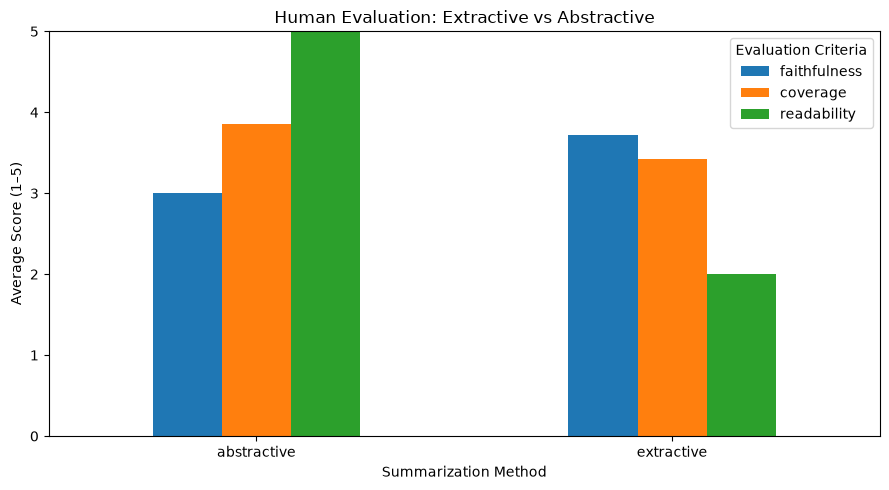

In [ ]:
#Human evaluation ka bar chart
import matplotlib.pyplot as plt

human_avg[["faithfulness", "coverage", "readability"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Human Evaluation: Extractive vs Abstractive")
plt.xlabel("Summarization Method")
plt.ylabel("Average Score (1–5)")
plt.ylim(0, 5)
plt.xticks(rotation=0)
plt.legend(title="Evaluation Criteria")
plt.tight_layout()
plt.show()

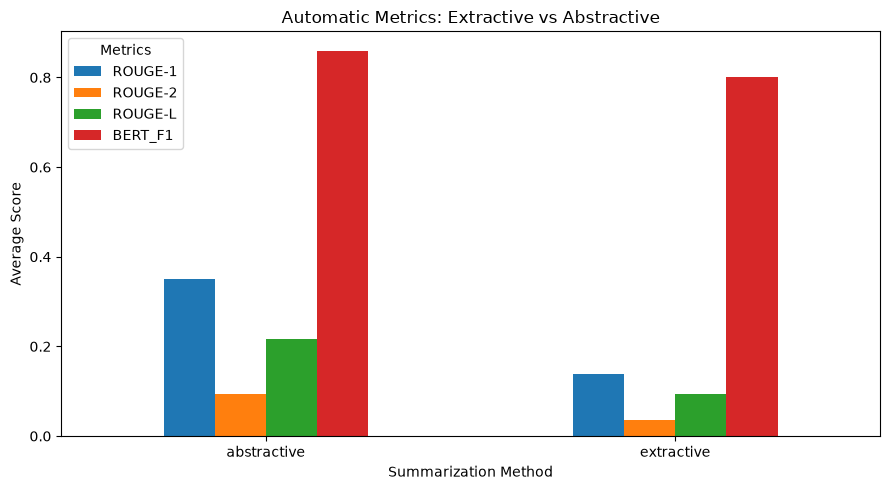

In [106]:
#same grapg for rouge and bert scores
auto_avg[["ROUGE-1", "ROUGE-2", "ROUGE-L", "BERT_F1"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Automatic Metrics: Extractive vs Abstractive")
plt.xlabel("Summarization Method")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()